# 2 · Direct YOLO training and native comparative evaluation

Run notebook 1 first. This notebook operates **only on its exported YOLO datasets**.
There are no custom filtering hooks in training, inference or validation, no custom
IoU/AP implementation, no detector abstraction, and no prediction-shard runner.

We ask two separate questions:
1. **Inference input effect:** one frozen raw-trained checkpoint, raw vs processed
   versions of the same test IDs/labels.
2. **Training data effect:** separately trained raw/processed models, evaluated on
   a common raw test set. The optional full matrix also shows cross-domain effects.

The following pilot is a small feasibility run. Best checkpoints are selected on
**tune from official train**, never on official-val test. Recipes/model settings
must be frozen before test. Once exposed, these pilot test IDs cannot become an
untouched final research holdout; notebook 1 records their exclusion.

In [1]:
import importlib.metadata as md
import io
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
from ultralytics import YOLO
from ultralytics.utils.ops import xywh2xyxy

from vehicle_detection.common import digest, file_hash, read_image, read_json, write_json
from vehicle_detection.data import CLASSES
from vehicle_detection.offline import verify_alignment

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
MODE = "pilot"
RUN_ROOT = ROOT / "runs" / f"notebook-{MODE}"
TRAIN_VARIANTS = ["raw", "gamma"]
EVAL_VARIANTS = ["raw", "gamma"]
MODEL = "yolo11n.pt"
SEED, EPOCHS, BATCH, IMGSZ, DEVICE = 2026, 3, 8, 640, "0"
EXPERIMENT_ROOT = RUN_ROOT / "experiments" / "yolo11n-seed2026-v1"
FROZEN_FOR_TEST = True  # For full research evaluation, freeze only after tune-only calibration.
VAL_SETTINGS = {
    "imgsz": IMGSZ,
    "batch": BATCH,
    "device": DEVICE,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "quantize": 32,
    "workers": 0,
    "plots": True,
    "verbose": False,
}
assert FROZEN_FOR_TEST and "raw" in TRAIN_VARIANTS and "raw" in EVAL_VARIANTS
VARIANTS = sorted(set(TRAIN_VARIANTS + EVAL_VARIANTS))
DATASETS = {v: RUN_ROOT / "datasets" / v for v in VARIANTS}
assert all((p / "data.yaml").is_file() for p in DATASETS.values()), "Run preparation notebook first"
print("Aligned exported images:", verify_alignment(DATASETS.values()))
selection = read_json(RUN_ROOT / "selection.json")
print("Split sizes:", {s: len(v) for s, v in selection["splits"].items()})
print("Each data.yaml: train=images/train, val=images/tune, test=images/test")
display(
    pd.Series(
        {p: md.version(p) for p in ["ultralytics", "torch", "torchvision", "numpy"]},
        name="versions",
    )
)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})

Aligned exported images: 96
Split sizes: {'test': 16, 'train': 64, 'tune': 16}
Each data.yaml: train=images/train, val=images/tune, test=images/test


ultralytics    8.4.198
torch           2.15.0
torchvision     0.29.2
numpy            2.4.6
Name: versions, dtype: object

## Independently train each dataset variant, with native checkpoints/resume

Every run starts from the **same pretrained file/hash**, has the same seed,
epochs/batch/resolution/device, and gets a distinct directory with best/last
checkpoints. Standard Ultralytics augmentation is comparable across variants.
An existing directory must match its saved configuration and export identity.
Completed runs verify best/last hashes and reuse them; interrupted runs use
`YOLO(last.pt).train(resume=True)`. No custom training/checkpoint engine is used.
Change `EXPERIMENT_ROOT` for different settings instead of mixing outputs.

In [2]:
initial = YOLO(MODEL)
pretrained = Path(initial.ckpt_path).resolve()
pretrained_sha256 = file_hash(pretrained)
print("Identical starting checkpoint:", pretrained.name, pretrained_sha256)
checkpoints, training_log = {}, []
for variant in TRAIN_VARIANTS:
    directory = EXPERIMENT_ROOT / variant
    identity = {
        "variant": variant,
        "seed": SEED,
        "epochs": EPOCHS,
        "batch": BATCH,
        "imgsz": IMGSZ,
        "device": DEVICE,
        "pretrained_sha256": pretrained_sha256,
        "export": read_json(DATASETS[variant] / "export.json"),
        "versions": {p: md.version(p) for p in ["ultralytics", "torch", "torchvision"]},
    }
    config_path = directory / "study.json"
    if config_path.exists():
        if read_json(config_path) != identity:
            raise ValueError(f"Experiment settings/dataset changed: {directory}")
    elif directory.exists() and any(directory.iterdir()):
        raise ValueError(f"Unknown existing experiment: {directory}")
    else:
        write_json(config_path, identity)
    best, last = directory / "weights/best.pt", directory / "weights/last.pt"
    completed = directory / "completed.json"
    if completed.exists():
        hashes = read_json(completed)
        assert hashes["study_identity"] == digest(identity)
        assert file_hash(best) == hashes["best_sha256"] and file_hash(last) == hashes["last_sha256"]
        status = "verified completed reuse"
    else:
        csv_path = directory / "results.csv"
        recorded = len(pd.read_csv(csv_path)) if csv_path.exists() else 0
        if recorded < EPOCHS or not best.exists() or not last.exists():
            if last.exists():
                YOLO(str(last)).train(resume=True)
                status = "native resume"
            else:
                YOLO(str(pretrained)).train(
                    data=str(DATASETS[variant] / "data.yaml"),
                    epochs=EPOCHS,
                    batch=BATCH,
                    imgsz=IMGSZ,
                    device=DEVICE,
                    seed=SEED,
                    deterministic=True,
                    workers=0,
                    project=str(EXPERIMENT_ROOT),
                    name=variant,
                    exist_ok=True,
                    plots=True,
                )
                status = "native fresh training"
        else:
            status = "completed native artifacts recovered"
        assert best.is_file() and last.is_file()
        assert len(pd.read_csv(directory / "results.csv")) >= EPOCHS
        write_json(
            completed,
            {
                "best_sha256": file_hash(best),
                "last_sha256": file_hash(last),
                "study_identity": digest(identity),
            },
        )
    checkpoints[variant] = best
    training_log.append(
        {
            "variant": variant,
            "status": status,
            "best": str(best),
            "last": str(last),
            "epochs": len(pd.read_csv(directory / "results.csv")),
        }
    )
display(pd.DataFrame(training_log))

Identical starting checkpoint: yolo11n.pt 0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1


,variant,status,best,last,epochs
0,raw,verified completed reuse,/mnt/d/Projects/vehicle-detection/runs/noteboo...,/mnt/d/Projects/vehicle-detection/runs/noteboo...,3
1,gamma,verified completed reuse,/mnt/d/Projects/vehicle-detection/runs/noteboo...,/mnt/d/Projects/vehicle-detection/runs/noteboo...,3


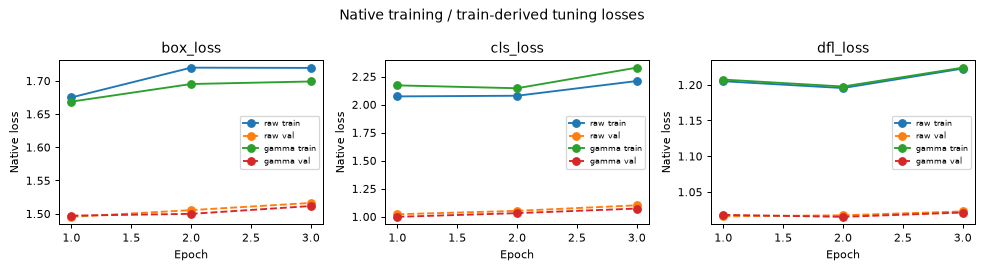

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for variant in TRAIN_VARIANTS:
    history = pd.read_csv(EXPERIMENT_ROOT / variant / "results.csv").rename(columns=str.strip)
    for ax, loss in zip(axes, ["box_loss", "cls_loss", "dfl_loss"], strict=True):
        for split, style in [("train", "-"), ("val", "--")]:
            key = f"{split}/{loss}"
            if key in history:
                ax.plot(history.epoch, history[key], style, marker="o", label=f"{variant} {split}")
        ax.set(title=loss, xlabel="Epoch", ylabel="Native loss")
        ax.legend(fontsize=6)
fig.suptitle("Native training / train-derived tuning losses")
fig.tight_layout()
plt.show()

## Freeze settings and evaluate both questions with native `model.val()`

Every comparison below uses the same exported test IDs and byte-identical label
files. `split='test'` is explicit; training's `val` remains tune. The raw checkpoint
hash is verified before/after the entire matrix. The whole matrix uses identical
native confidence/NMS/image-size/precision settings, without custom metrics.
Per-class AP uses only `ap_class_index`; absent classes are **not** assigned the
overall mAP through `box.maps`.

Timing is Ultralytics' native preprocessing/inference/postprocess speed on files
that are **already processed offline**. It excludes offline preparation and is
not measured online end-to-end latency or application throughput.

In [4]:
assert FROZEN_FOR_TEST
frozen_checkpoints = {v: file_hash(p) for v, p in checkpoints.items()}
evaluation_identity = {
    "selection": selection["selection_id"],
    "weights": frozen_checkpoints,
    "settings": VAL_SETTINGS,
    "train_variants": TRAIN_VARIANTS,
    "eval_variants": EVAL_VARIANTS,
}
identity_path = EXPERIMENT_ROOT / "evaluation.json"
if identity_path.exists() and read_json(identity_path) != evaluation_identity:
    raise ValueError("Evaluation settings/checkpoints changed; use a fresh experiment root")
write_json(identity_path, evaluation_identity)
rows, class_rows = [], []
for trained, best in checkpoints.items():
    for evaluated in EVAL_VARIANTS:
        output = EXPERIMENT_ROOT / "evaluation" / f"{trained}_on_{evaluated}"
        model = YOLO(str(best))
        runtime = {}
        model.add_callback(
            "on_val_start",
            lambda validator, runtime=runtime: runtime.update(device=str(validator.device)),
        )
        metrics = model.val(
            data=str(DATASETS[evaluated] / "data.yaml"),
            split="test",
            project=str(output.parent),
            name=output.name,
            exist_ok=True,
            **VAL_SETTINGS,
        )
        assert model.names == dict(enumerate(CLASSES))
        assert runtime["device"] == (f"cuda:{DEVICE}" if DEVICE.isdigit() else DEVICE)
        values = [metrics.box.map50, metrics.box.map, metrics.box.mp, metrics.box.mr]
        assert np.isfinite(values).all() and all(0 <= x <= 1 for x in values)
        row = {
            "trained_on": trained,
            "evaluated_on": evaluated,
            "test_images": len(selection["splits"]["test"]),
            "mAP50": float(metrics.box.map50),
            "mAP50_95": float(metrics.box.map),
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
            "checkpoint_sha256": frozen_checkpoints[trained],
            "actual_device": runtime["device"],
            **{f"{k}_ms": float(v) for k, v in metrics.speed.items()},
        }
        row["native_stage_ms"] = sum(metrics.speed.values())
        rows.append(row)
        for j, cls in enumerate(metrics.box.ap_class_index):
            class_rows.append(
                {
                    "trained_on": trained,
                    "evaluated_on": evaluated,
                    "class": CLASSES[int(cls)],
                    "AP50": float(metrics.box.ap50[j]),
                    "AP50_95": float(metrics.box.ap[j]),
                }
            )
assert all(file_hash(checkpoints[v]) == sha for v, sha in frozen_checkpoints.items())
results = pd.DataFrame(rows)
per_class = pd.DataFrame(class_rows)
results.to_csv(EXPERIMENT_ROOT / "results.csv", index=False)
write_json(EXPERIMENT_ROOT / "results.json", results.to_dict("records"))
per_class.to_csv(EXPERIMENT_ROOT / "per_class_AP.csv", index=False)
display(results.drop(columns=["checkpoint_sha256"]).round(5))
display(
    per_class.pivot(index=["trained_on", "evaluated_on"], columns="class", values="AP50_95")
    .reindex(columns=CLASSES)
    .round(5)
)

Ultralytics 8.4.198 🚀 Python-3.11.14 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16284MiB)


YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs


WARNING ⚠️ val: Slow image access detected (ping: 2.5±0.5 ms, read: 22.3±5.5 MB/s, size: 64.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips


val: Scanning /mnt/d/Projects/vehicle-detection/runs/notebook-pilot/datasets/raw/labels/test.cache... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 5.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 1.3it/s 0.2s<0.8s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 5.9it/s 0.3s

... (27 outputs left out)

Speed: 0.5ms preprocess, 5.6ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to /mnt/d/Projects/vehicle-detection/runs/notebook-pilot/experiments/yolo11n-seed2026-v1/evaluation/gamma_on_gamma


,trained_on,evaluated_on,test_images,mAP50,mAP50_95,precision,recall,actual_device,preprocess_ms,inference_ms,loss_ms,postprocess_ms,native_stage_ms
0,raw,raw,16,0.64342,0.39721,0.45876,0.67702,cuda:0,0.20919,3.54535,0.00066,2.14915,5.90436
1,raw,gamma,16,0.60779,0.37370,0.46297,0.68508,cuda:0,0.18361,1.50534,0.00045,0.75099,2.44040
2,gamma,raw,16,0.62582,0.36170,0.47529,0.67710,cuda:0,0.12578,1.07053,0.00042,0.58370,1.78042
3,gamma,gamma,16,0.61819,0.36010,0.45756,0.68024,cuda:0,0.47588,5.56508,0.00049,0.71492,6.75638


class                        car    truck      bus  train  motorcycle  bicycle
trained_on evaluated_on                                                       
gamma      gamma         0.25955  0.26724  0.56536    NaN         NaN  0.34825
           raw           0.26083  0.31141  0.52632    NaN         NaN  0.34825
raw        gamma         0.26114  0.24655  0.56425    NaN         NaN  0.42288
           raw           0.25536  0.31977  0.59083    NaN         NaN  0.42288

Q1 — Same frozen raw checkpoint, changed offline inference images:


,mAP50,mAP50_95,inference_ms,native_stage_ms
evaluated_on,,,,
raw,0.64342,0.39721,3.54535,5.90436
gamma,0.60779,0.37370,1.50534,2.44040


Q2 — Separately trained checkpoints, common raw test images:


,mAP50,mAP50_95,inference_ms,native_stage_ms
trained_on,,,,
raw,0.64342,0.39721,3.54535,5.90436
gamma,0.62582,0.36170,1.07053,1.78042


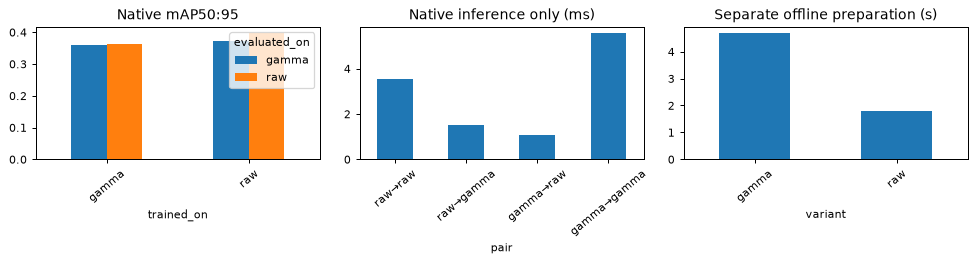

In [5]:
frozen_raw = results[results.trained_on == "raw"].set_index("evaluated_on")
common_test = results[results.evaluated_on == "raw"].set_index("trained_on")
print("Q1 — Same frozen raw checkpoint, changed offline inference images:")
display(frozen_raw[["mAP50", "mAP50_95", "inference_ms", "native_stage_ms"]].round(5))
print("Q2 — Separately trained checkpoints, common raw test images:")
display(common_test[["mAP50", "mAP50_95", "inference_ms", "native_stage_ms"]].round(5))
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
results.pivot(index="trained_on", columns="evaluated_on", values="mAP50_95").plot.bar(
    ax=axes[0], title="Native mAP50:95"
)
results.assign(pair=results.trained_on + "→" + results.evaluated_on).set_index(
    "pair"
).inference_ms.plot.bar(ax=axes[1], title="Native inference only (ms)")
preparation = pd.read_csv(RUN_ROOT / "preparation_cost.csv").set_index("variant")
(preparation.preparation_ms / 1000).plot.bar(ax=axes[2], title="Separate offline preparation (s)")
for ax in axes:
    ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
plt.show()

confusion_matrix_normalized.png


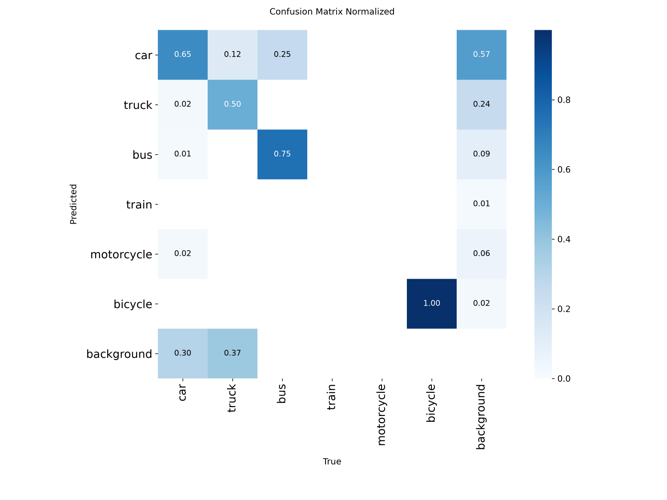

BoxPR_curve.png


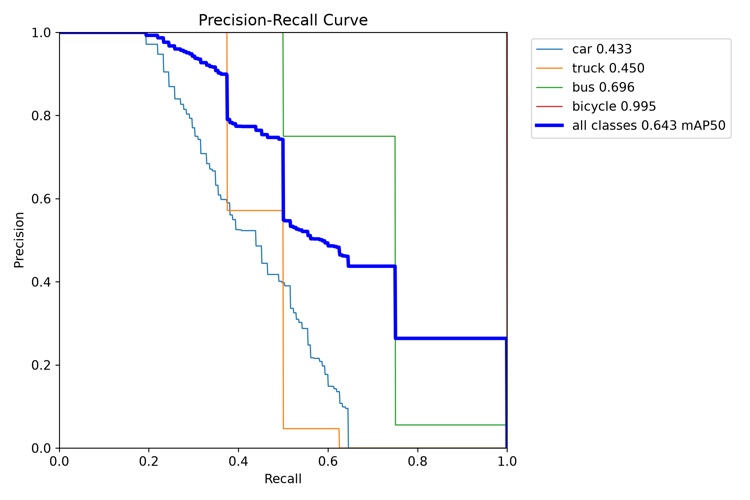

All matrix plots, labels/prediction grids and curves remain under each evaluation directory.


In [6]:
def show_native_plot(path):
    with PILImage.open(path) as im:
        im.thumbnail((800, 500))
        buffer = io.BytesIO()
        im.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


baseline_plots = EXPERIMENT_ROOT / "evaluation/raw_on_raw"
for pattern in ["confusion_matrix_normalized.png", "*PR_curve.png"]:
    paths = sorted(baseline_plots.glob(pattern))
    assert paths, f"Native plot missing: {pattern}"
    print(paths[0].name)
    show_native_plot(paths[0])
print(
    "All matrix plots, labels/prediction grids and curves remain under each evaluation directory."
)

## Inspect diagnostic failure examples — no handwritten matching/AP

The following examples rank absolute **GT vs predicted object-count differences**
at display confidence 0.25. This is only a cheap diagnostic: equal counts do not
imply correct localization/classes, and it is not AP or an accuracy ranking.
Native confusion matrices and PR curves above provide the quantitative analysis.
Native predictions below read exported raw test files; no custom filtering occurs.

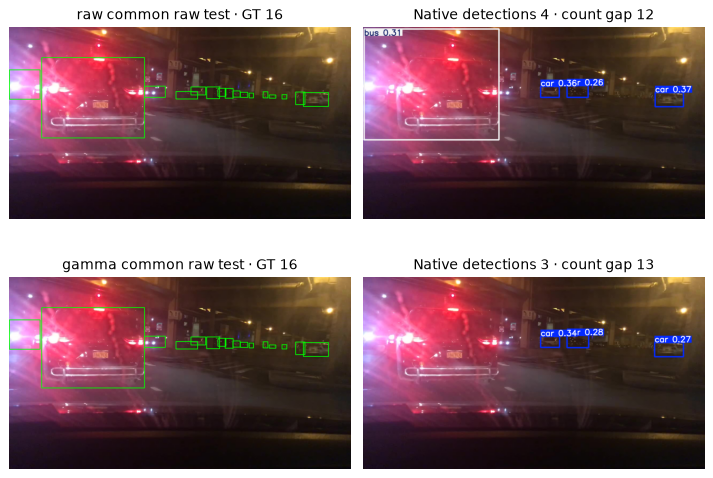

,trained_on,id,GT_count,prediction_count,count_gap
0,raw,c3f8a4ce-2090da6b,16,4,12
1,gamma,c3f8a4ce-2090da6b,16,3,13


In [7]:
meta = pd.read_csv(DATASETS["raw"] / "metadata.csv")
test_rows = meta[meta.split == "test"].to_dict("records")
fig, axes = plt.subplots(
    len(TRAIN_VARIANTS), 2, figsize=(8, 3 * len(TRAIN_VARIANTS)), squeeze=False
)
failure_rows = []
for i, variant in enumerate(TRAIN_VARIANTS):
    candidates = []
    predictor = YOLO(str(checkpoints[variant]))
    for r, pred in zip(
        test_rows,
        predictor.predict(
            source=[r["image"] for r in test_rows],
            stream=True,
            device=DEVICE,
            imgsz=IMGSZ,
            conf=0.25,
            quantize=32,
            verbose=False,
        ),
        strict=True,
    ):
        label = DATASETS["raw"] / "labels/test" / f"{r['id']}.txt"
        text = label.read_text().strip()
        gt = np.loadtxt(label, ndmin=2).reshape(-1, 5) if text else np.empty((0, 5))
        candidates.append((abs(len(gt) - len(pred.boxes)), r, pred, gt))
    gap, r, pred, gt = max(candidates, key=lambda item: (item[0], item[1]["id"]))
    image = read_image(r["image"])
    h, w = image.shape[:2]
    for box in xywh2xyxy(gt[:, 1:] * np.array([w, h, w, h])):
        x1, y1, x2, y2 = map(round, box)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    axes[i, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{variant} common raw test · GT {len(gt)}")
    axes[i, 1].imshow(cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"Native detections {len(pred.boxes)} · count gap {gap}")
    failure_rows.append(
        {
            "trained_on": variant,
            "id": r["id"],
            "GT_count": len(gt),
            "prediction_count": len(pred.boxes),
            "count_gap": gap,
        }
    )
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
plt.show()
display(pd.DataFrame(failure_rows))

In [8]:
# Check completed-run reuse without another optimizer step.
for variant in TRAIN_VARIANTS:
    directory = EXPERIMENT_ROOT / variant
    saved = read_json(directory / "completed.json")
    assert file_hash(checkpoints[variant]) == saved["best_sha256"]
    assert file_hash(directory / "weights/last.pt") == saved["last_sha256"]
assert verify_alignment(DATASETS.values()) == sum(len(v) for v in selection["splits"].values())
validation = {
    "mode": "real BDD offline export + separately trained YOLO + native model.val, no mocks",
    "selection_id": selection["selection_id"],
    "split_sizes": {s: len(v) for s, v in selection["splits"].items()},
    "epochs": EPOCHS,
    "model": MODEL,
    "seed": SEED,
    "device": DEVICE,
    "checkpoint_sha256": frozen_checkpoints,
    "evaluated_pairs": len(results),
    "native_metrics": True,
    "online_filtering": False,
    "versions": {p: md.version(p) for p in ["bdd100k", "scalabel", "ultralytics", "torch"]},
}
write_json(EXPERIMENT_ROOT / "validation.json", validation)
display(validation)
print("PASS: frozen models, aligned native matrix and completed checkpoint reuse")

{'mode': 'real BDD offline export + separately trained YOLO + native model.val, no mocks',
 'selection_id': 'ad479d30c4c1269bddf52bd31cfb8ba91153f692aba043fa5ff871fd89e2c4fa',
 'split_sizes': {'test': 16, 'train': 64, 'tune': 16},
 'epochs': 3,
 'model': 'yolo11n.pt',
 'seed': 2026,
 'device': '0',
 'checkpoint_sha256': {'raw': 'ad57a058505d8542c4cda344ebae0c46b3b6dc29c0ea9698ba235b5cfce91403',
  'gamma': '6d1e4c5907a3f1e47017d54b42c58ef924cf98fa1d69ce337a00ea74c1b27d43'},
 'evaluated_pairs': 4,
 'native_metrics': True,
 'online_filtering': False,
 'versions': {'bdd100k': '1.0.1',
  'scalabel': '0.3.1',
  'ultralytics': '8.4.198',
  'torch': '2.15.0'}}

PASS: frozen models, aligned native matrix and completed checkpoint reuse


## Interpretation and limits

These are **pilot** scores with very limited rare-class support, not full-study
conclusions. No rule/model is selected from test results. Gamma=0.65 and all other
recipe settings were fixed before this execution and were not calibrated using
these test images. A real full study needs train/tune-only policy calibration,
frozen recipes/models, a fresh unexposed official-val test subset, repeated seeds
and uncertainty analysis. Optional mixed training and synthetic stress datasets
are not included in this minimal workflow.

Native speed covers preprocessed-file model stages, **not** offline preparation,
application throughput, or online end-to-end latency. Preparation costs and disk
usage are shown separately. Artifacts remain under `runs/`; only these compact
executed notebook outputs and source files belong in Git.

With only a few pilot validation batches, native speed can be dominated by warm-up, batch order and caching. Do not use these timings as a reliable latency ranking.